# Augmentation 

In [28]:
#Imports 
import os
import sys
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F

from PIL import Image

from datasets import load_dataset

from transformers import (
    Sam2Model,
    Sam2Processor,
)

from torchvision import transforms

from tqdm.auto import tqdm

In [29]:

#Paths registry 
PROJECT_ROOT = Path("/home/zahranadeem/thesis")

MODEL_NAME = "facebook/sam2.1-hiera-tiny"

###############################################

AGRICLIP_ROOT = (
    PROJECT_ROOT
    / "agriclip_sam2"
    / "AgriCLIP"
)

ALIGNMENT_DIR = (
    AGRICLIP_ROOT
    / "AgriCLIP_alignment"
)

ALIGNER_PATH = (
    PROJECT_ROOT
    / "vegann_aligner.pth"
)

SAM2_CHECKPOINT = (
    PROJECT_ROOT
    / "sam2_vegann_checkpoints"
    / "best_sam2_vegann_mask_decoder.pt"
)

OUTPUT_DIR = (
    PROJECT_ROOT
    / "results"
    / "agriclip_attention_guided_sam2"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

print("Project:", PROJECT_ROOT)
print("AgriCLIP:", AGRICLIP_ROOT)
print("Aligner:", ALIGNER_PATH)
print("SAM2:", SAM2_CHECKPOINT)


Project: /home/zahranadeem/thesis
AgriCLIP: /home/zahranadeem/thesis/agriclip_sam2/AgriCLIP
Aligner: /home/zahranadeem/thesis/vegann_aligner.pth
SAM2: /home/zahranadeem/thesis/sam2_vegann_checkpoints/best_sam2_vegann_mask_decoder.pt


In [30]:
#Checking the device 
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print(device)

cuda


In [31]:
#Loading VegAnn and split 
vegann = load_dataset(
    "simonMadec/VegAnn"
)

split = vegann["train"].train_test_split(
    test_size=0.20,
    seed=42
)

train_hf = split["train"]
val_hf = split["test"]

print(len(train_hf))
print(len(val_hf))

3020
755


In [32]:
#Detecting image and mask coloums 
columns = vegann["train"].column_names

IMAGE_KEY = next(
    x
    for x in columns
    if x in ["image", "images", "rgb"]
)

MASK_KEY = next(
    x
    for x in columns
    if x in [
        "mask",
        "masks",
        "label",
        "labels",
        "segmentation_mask",
    ]
)

print(IMAGE_KEY)
print(MASK_KEY)

image
mask


In [33]:
#Image helper
def get_image(index, split=val_hf):

    sample = split[index]

    image = sample[IMAGE_KEY]

    if not isinstance(image, Image.Image):
        image = Image.fromarray(np.array(image))

    return image.convert("RGB")


def get_mask(index, split=val_hf):

    sample = split[index]

    mask = np.array(sample[MASK_KEY])

    mask = (mask > 0).astype(np.uint8)

    return mask

In [34]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print(f"Random seed set to {SEED}")

Random seed set to 42


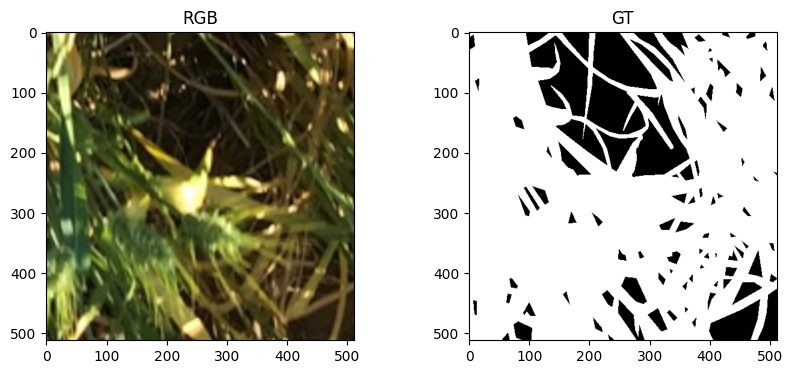

In [35]:
#Visualize image and mask 
image = get_image(0)
mask = get_mask(0)

plt.figure(figsize=(10,4))

plt.subplot(121)
plt.imshow(image)
plt.title("RGB")

plt.subplot(122)
plt.imshow(mask,cmap="gray")
plt.title("GT")

plt.show()

In [36]:
#Transform the image 
IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406,
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225,
]

dino_transform = transforms.Compose([

    transforms.Resize(
        (224,224)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        IMAGENET_MEAN,
        IMAGENET_STD,
    ),
])

In [37]:
#Load DINO 
dino_model = torch.hub.load(
    "facebookresearch/dino:main",
    "dino_resnet50",
    pretrained=True,
)

dino_model.eval()
dino_model.to(device)

for parameter in dino_model.parameters():
    parameter.requires_grad = False

print("DINO loaded.")

Using cache found in /home/zahranadeem/.cache/torch/hub/facebookresearch_dino_main
/home/zahranadeem/thesis/agriclip_sam2/agriclip_env/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/zahranadeem/thesis/agriclip_sam2/agriclip_env/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


DINO loaded.


In [38]:
import sys

ALIGNMENT_DIR = "/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/AgriCLIP_alignment"

if ALIGNMENT_DIR not in sys.path:
    sys.path.append(ALIGNMENT_DIR)

from TextToConcept import TextToConcept
from LinearAligner import LinearAligner

print("Imported successfully")

Imported successfully


In [39]:
text_to_concept = TextToConcept(
    dino_model,
    "dino_resnet50",
)

text_to_concept.load_linear_aligner(
    str(ALIGNER_PATH)
)

aligner = text_to_concept.linear_aligner

print("VegAnn aligner loaded.")
print("W shape:", tuple(aligner.W.shape))
print("b shape:", tuple(aligner.b.shape))

VegAnn aligner loaded.
W shape: (512, 2048)
b shape: (512,)


In [40]:
#Register a hook on Dino layer4
captured_feature_map = None


def capture_layer4_output(module, inputs, output):
    global captured_feature_map
    captured_feature_map = output.detach()


hook_handle = dino_model.layer4.register_forward_hook(
    capture_layer4_output
)

print("DINO layer4 hook registered.")

DINO layer4 hook registered.


In [41]:
#Extract spatial DINO descriptors automatically wheter 7x7 or other
@torch.no_grad()
def extract_dino_patch_features(pil_image):
    
    

    global captured_feature_map

    captured_feature_map = None

    image_tensor = dino_transform(
        pil_image
    ).unsqueeze(0).to(device)

    _ = dino_model(image_tensor)

    if captured_feature_map is None:
        raise RuntimeError(
            "The layer4 hook did not capture a feature map."
        )

    if captured_feature_map.ndim != 4:
        raise RuntimeError(
            "Expected feature map shape (B, C, H, W), "
            f"but received {captured_feature_map.shape}."
        )

    _, channels, grid_h, grid_w = captured_feature_map.shape

    patch_features = (
        captured_feature_map[0]
        .permute(1, 2, 0)
        .reshape(grid_h * grid_w, channels)
        .contiguous()
    )

    return patch_features, grid_h, grid_w

In [42]:
#Extract patches 
sample_index = 0

image = get_image(
    sample_index,
    split=val_hf,
)

gt_mask = get_mask(
    sample_index,
    split=val_hf,
)

patch_features, grid_h, grid_w = extract_dino_patch_features(
    image
)

print("Image size:", image.size)
print("Feature grid:", grid_h, "x", grid_w)
print("Patch features:", patch_features.shape)

Image size: (512, 512)
Feature grid: 7 x 7
Patch features: torch.Size([49, 2048])


In [43]:
print(
    "DINO feature dim:",
    patch_features.shape
)

print(
    "Aligner input:",
    aligner.W.shape
)

DINO feature dim: torch.Size([49, 2048])
Aligner input: torch.Size([512, 2048])


In [44]:
#Project patches using VegAnn aligner 
#Better to project first and then normalize in a shared concept space
@torch.no_grad()
def align_patch_features(patch_features):
    patch_features = patch_features.float().to(device)

    aligned_features = aligner.get_aligned_representation(
        patch_features
    )

    aligned_features = F.normalize(
        aligned_features,
        dim=1,
    )

    return aligned_features


aligned_patch_features = align_patch_features(
    patch_features
)

print("Aligned patch features:", aligned_patch_features.shape)

Aligned patch features: torch.Size([49, 512])


In [45]:
# Positive negative prompts 

POSITIVE_PROMPTS = [

    "vegetation",
    "green vegetation",
    "crop plants",
    "crop vegetation",
    "agricultural plants",
    "green plants",
]

NEGATIVE_PROMPTS = [

    "soil",
    "bare soil",
    "ground",
    "bare ground",
    "non-vegetated ground",
    "agricultural soil",
]

print("Prompt strategy: POSITIVE / NEGATIVE")

print("\nPositive prompts:")
for i, prompt in enumerate(POSITIVE_PROMPTS, 1):
    print(f"{i}. {prompt}")

print("\nNegative prompts:")
for i, prompt in enumerate(NEGATIVE_PROMPTS, 1):
    print(f"{i}. {prompt}")
    
    
    


Prompt strategy: POSITIVE / NEGATIVE

Positive prompts:
1. vegetation
2. green vegetation
3. crop plants
4. crop vegetation
5. agricultural plants
6. green plants

Negative prompts:
1. soil
2. bare soil
3. ground
4. bare ground
5. non-vegetated ground
6. agricultural soil


In [46]:
@torch.no_grad()
def encode_prompt_set(prompts):

    embeddings = []

    for prompt in prompts:

        embedding = text_to_concept.encode_text(
            [[prompt]]
        )

        if isinstance(embedding, np.ndarray):
            embedding = torch.from_numpy(
                embedding
            )

        if not torch.is_tensor(embedding):
            raise TypeError(
                "encode_text returned an unsupported type: "
                f"{type(embedding)}"
            )

        embedding = (
            embedding
            .detach()
            .float()
            .to(device)
            .reshape(-1)
        )

        embeddings.append(
            embedding
        )

    embeddings = torch.stack(
        embeddings,
        dim=0
    )

    # Normalize each prompt independently
    embeddings = F.normalize(
        embeddings,
        dim=1
    )

    # Average prompts
    mean_embedding = embeddings.mean(
        dim=0
    )

    # Normalize the averaged embedding
    mean_embedding = F.normalize(
        mean_embedding,
        dim=0
    )

    return embeddings, mean_embedding


# ------------------------------------------------------------
# POSITIVE
# ------------------------------------------------------------

positive_text_embeddings, positive_embedding = (
    encode_prompt_set(
        POSITIVE_PROMPTS
    )
)


# ------------------------------------------------------------
# NEGATIVE
# ------------------------------------------------------------

negative_text_embeddings, negative_embedding = (
    encode_prompt_set(
        NEGATIVE_PROMPTS
    )
)


print(
    "Positive embeddings:",
    positive_text_embeddings.shape
)

print(
    "Negative embeddings:",
    negative_text_embeddings.shape
)

print(
    "Positive mean embedding:",
    positive_embedding.shape
)

print(
    "Negative mean embedding:",
    negative_embedding.shape
)

Positive embeddings: torch.Size([6, 512])
Negative embeddings: torch.Size([6, 512])
Positive mean embedding: torch.Size([512])
Negative mean embedding: torch.Size([512])


In [47]:
# ============================================================
# POSITIVE - NEGATIVE CONCEPT
# ============================================================

vegetation_embedding = (
    positive_embedding
    - negative_embedding
)

vegetation_embedding = F.normalize(
    vegetation_embedding,
    dim=0
)

print(
    "Final vegetation embedding:",
    vegetation_embedding.shape
)

Final vegetation embedding: torch.Size([512])


In [48]:
import sys
from pathlib import Path

ALIGNMENT_DIR = Path(
    "/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/AgriCLIP_alignment"
)

if str(ALIGNMENT_DIR) not in sys.path:
    sys.path.insert(0, str(ALIGNMENT_DIR))

print(sys.path[0])

/usr/lib/python310.zip


In [49]:
from TextToConcept import TextToConcept
from LinearAligner import LinearAligner

print("Imported successfully")

Imported successfully


In [50]:
print(type(text_to_concept))
print(text_to_concept.__dict__.keys())

<class 'TextToConcept.TextToConcept'>
dict_keys(['model', 'model_name', 'device', 'clip_model', 'saved_dsets', 'linear_aligner'])


In [51]:
print(hasattr(text_to_concept, "tokenizer"))
print(hasattr(text_to_concept, "model"))

if hasattr(text_to_concept, "tokenizer"):
    print(type(text_to_concept.tokenizer))

if hasattr(text_to_concept, "model"):
    print(type(text_to_concept.model))

False
True
<class 'torchvision.models.resnet.ResNet'>


In [52]:
# Compute AgriCLIP patch-text similarity scores

with torch.no_grad():

    patch_scores = (
        aligned_patch_features 
        @ vegetation_embedding
    )

print("Patch scores shape:", patch_scores.shape)
print("Min:", patch_scores.min().item())
print("Max:", patch_scores.max().item())

Patch scores shape: torch.Size([49])
Min: -0.020329272374510765
Max: 0.14176683127880096


In [53]:
TOP_K =  32
scores = patch_scores.cpu().numpy()

sorted_indices = np.argsort(scores)[::-1]

topk_indices = sorted_indices[:TOP_K]

print("Top-K patch indices:")
print(topk_indices)

print("Scores:")
print(scores[topk_indices])

Top-K patch indices:
[13 43  6 20 29 10  1 47 18  8 46 22 19  2  3 26 17 36 34 33 23 35 40 15
 30 12 21  7 14 41 11 28]
Scores:
[0.14176683 0.1323612  0.13027082 0.12215064 0.12186894 0.12176584
 0.1201911  0.1149954  0.11485691 0.11447184 0.11091828 0.10906088
 0.10504849 0.10468902 0.10449479 0.10404819 0.10284875 0.10084666
 0.09749009 0.09741492 0.09656537 0.09646869 0.09443323 0.09212168
 0.09189506 0.09112763 0.09039424 0.0843125  0.08208122 0.07708293
 0.07664943 0.07642687]


In [54]:
PATCH_ROWS = 7
PATCH_COLS = 7

H, W = image.size[1], image.size[0]

patch_h = H / PATCH_ROWS
patch_w = W / PATCH_COLS

boxes = []

for idx in topk_indices:

    r = idx // PATCH_COLS
    c = idx % PATCH_COLS

    x1 = int(c * patch_w)
    y1 = int(r * patch_h)

    x2 = int((c + 1) * patch_w)
    y2 = int((r + 1) * patch_h)

    boxes.append([x1, y1, x2, y2])

boxes = np.array(boxes)

print(boxes)

[[438  73 512 146]
 [ 73 438 146 512]
 [438   0 512  73]
 [438 146 512 219]
 [ 73 292 146 365]
 [219  73 292 146]
 [ 73   0 146  73]
 [365 438 438 512]
 [292 146 365 219]
 [ 73  73 146 146]
 [292 438 365 512]
 [ 73 219 146 292]
 [365 146 438 219]
 [146   0 219  73]
 [219   0 292  73]
 [365 219 438 292]
 [219 146 292 219]
 [ 73 365 146 438]
 [438 292 512 365]
 [365 292 438 365]
 [146 219 219 292]
 [  0 365  73 438]
 [365 365 438 438]
 [ 73 146 146 219]
 [146 292 219 365]
 [365  73 438 146]
 [  0 219  73 292]
 [  0  73  73 146]
 [  0 146  73 219]
 [438 365 512 438]
 [292  73 365 146]
 [  0 292  73 365]]


In [55]:
xmin = boxes[:,0].min()
ymin = boxes[:,1].min()

xmax = boxes[:,2].max()
ymax = boxes[:,3].max()

merged_box = np.array(
    [
        xmin,
        ymin,
        xmax,
        ymax
    ],
    dtype=np.int32
)

print(merged_box)

[  0   0 512 512]


In [56]:
margin = 25

xmin = max(0, xmin - margin)
ymin = max(0, ymin - margin)

xmax = min(W-1, xmax + margin)
ymax = min(H-1, ymax + margin)

merged_box = np.array(
    [
        xmin,
        ymin,
        xmax,
        ymax
    ]
)

print(merged_box)

[  0   0 511 511]


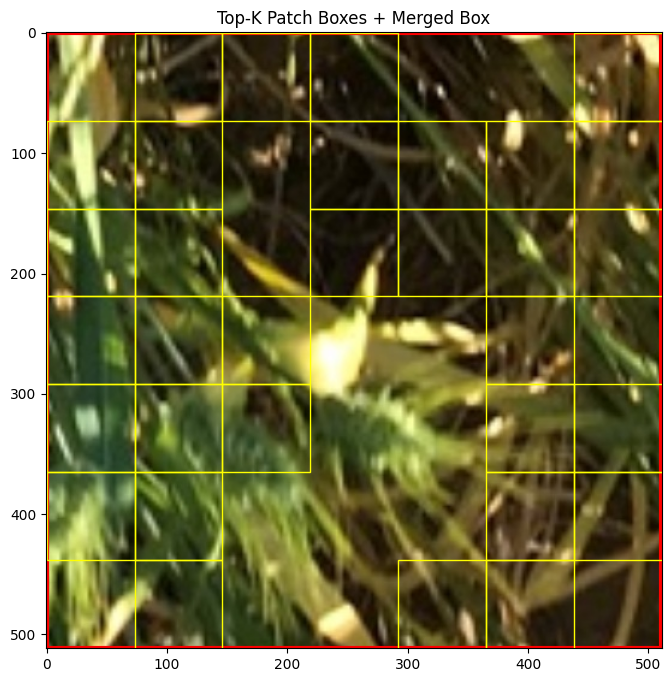

In [57]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(8,8))

ax.imshow(image)

rect = patches.Rectangle(

    (merged_box[0], merged_box[1]),

    merged_box[2]-merged_box[0],

    merged_box[3]-merged_box[1],

    linewidth=3,

    edgecolor="red",

    facecolor="none",

)

ax.add_patch(rect)

for b in boxes:

    rect = patches.Rectangle(

        (b[0], b[1]),

        b[2]-b[0],

        b[3]-b[1],

        linewidth=1,

        edgecolor="yellow",

        facecolor="none",

    )

    ax.add_patch(rect)

plt.title("Top-K Patch Boxes + Merged Box")

plt.show()

In [58]:
print("Merged Box:", merged_box)

print("Image size:", image.size)

print("GT foreground:", gt_mask.sum())

Merged Box: [  0   0 511 511]
Image size: (512, 512)
GT foreground: 208628


In [59]:
#Load fine tuned SAM2 model 
sam2_processor = Sam2Processor.from_pretrained(
    MODEL_NAME
)

sam2_model = Sam2Model.from_pretrained(
    MODEL_NAME
)

sam2_checkpoint = torch.load(
    SAM2_CHECKPOINT,
    map_location="cpu",
)

print("SAM2 checkpoint type:", type(sam2_checkpoint))

if (
    isinstance(sam2_checkpoint, dict)
    and "mask_decoder_state_dict" in sam2_checkpoint
):
    mask_decoder_state_dict = sam2_checkpoint[
        "mask_decoder_state_dict"
    ]
elif isinstance(sam2_checkpoint, dict):
    # Supports a checkpoint that directly contains decoder weights.
    mask_decoder_state_dict = sam2_checkpoint
else:
    raise TypeError(
        "Unsupported SAM2 checkpoint structure."
    )

load_result = sam2_model.mask_decoder.load_state_dict(
    mask_decoder_state_dict,
    strict=True,
)

sam2_model = sam2_model.to(device)
sam2_model.eval()

print("Fine-tuned SAM2 mask decoder loaded.")
print(load_result)

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

SAM2 checkpoint type: <class 'dict'>
Fine-tuned SAM2 mask decoder loaded.
<All keys matched successfully>


In [60]:
checkpoint = torch.load(
    SAM2_CHECKPOINT,
    map_location=device
)

print(checkpoint.keys())

dict_keys(['epoch', 'model_name', 'mask_decoder_state_dict', 'optimizer_state_dict', 'best_mean_iou', 'history'])


In [61]:
sam2_inputs = sam2_processor(

    images=image,

    input_boxes=[[merged_box]],
    #input_boxes = [[gt_box]],

    return_tensors="pt",

)

sam2_inputs = {

    k: v.to(device)

    if torch.is_tensor(v)

    else v

    for k, v in sam2_inputs.items()

}

with torch.no_grad():

    sam2_outputs = sam2_model(
        **sam2_inputs
    )

print(sam2_outputs.pred_masks.shape)
print(sam2_outputs.iou_scores.shape)

torch.Size([1, 1, 3, 256, 256])
torch.Size([1, 1, 3])


In [62]:
# Pick best candidate

best_index = sam2_outputs.iou_scores[0,0].argmax()

print("Best candidate:", best_index.item())

# Raw logits

best_logits = sam2_outputs.pred_masks[
    0,
    0,
    best_index
]

print(best_logits.shape)

# Convert to probability

best_mask_probability = torch.sigmoid(best_logits)

# Resize to original image size

best_mask_probability = torch.nn.functional.interpolate(

    best_mask_probability.unsqueeze(0).unsqueeze(0),

    size=gt_mask.shape,

    mode="bilinear",

    align_corners=False,

).squeeze()

best_mask = (

    best_mask_probability > 0.15

).cpu().numpy().astype(np.uint8)

print(best_mask.shape)

Best candidate: 2
torch.Size([256, 256])
(512, 512)


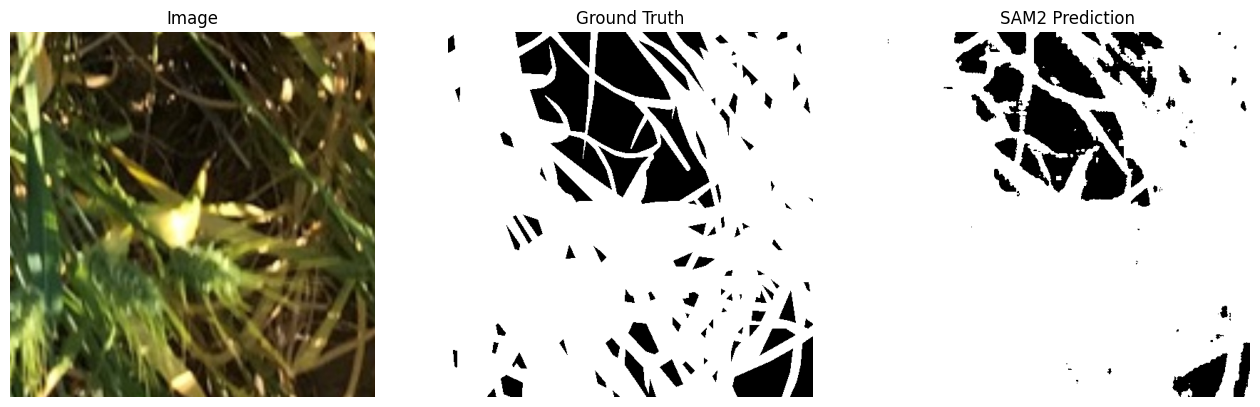

In [63]:
plt.figure(figsize=(16,5))

plt.subplot(131)
plt.imshow(image)
plt.title("Image")
plt.axis("off")

plt.subplot(132)
plt.imshow(gt_mask,cmap="gray")
plt.title("Ground Truth")
plt.axis("off")

plt.subplot(133)
plt.imshow(best_mask,cmap="gray")
plt.title("SAM2 Prediction")
plt.axis("off")

plt.show()

In [64]:
#Select and decode the best SAM2 candidate 
best_candidate_index = int(
    sam2_outputs.iou_scores[0, 0]
    .argmax()
    .item()
)

best_mask_logits = sam2_outputs.pred_masks[
    0,
    0,
    best_candidate_index,
]

best_mask_probability = torch.sigmoid(
    best_mask_logits
)

original_height = int(
    sam2_inputs["original_sizes"][0, 0].item()
)
original_width = int(
    sam2_inputs["original_sizes"][0, 1].item()
)

best_mask_probability = F.interpolate(
    best_mask_probability[None, None],
    size=(original_height, original_width),
    mode="bilinear",
    align_corners=False,
)[0, 0]

pred_mask = (
    best_mask_probability >= 0.5
).detach().cpu().numpy().astype(np.uint8)

print("Selected SAM2 candidate:", best_candidate_index)
print(
    "Predicted IoU confidence:",
    float(
        sam2_outputs.iou_scores[
            0,
            0,
            best_candidate_index,
        ].item()
    ),
)
print("Prediction shape:", pred_mask.shape)
print("Foreground pixels:", int(pred_mask.sum()))

Selected SAM2 candidate: 2
Predicted IoU confidence: 0.9524438381195068
Prediction shape: (512, 512)
Foreground pixels: 208917


Min : 2.7819598e-05
Max : 0.99997604
Mean: 0.7812024
Std : 0.34581533


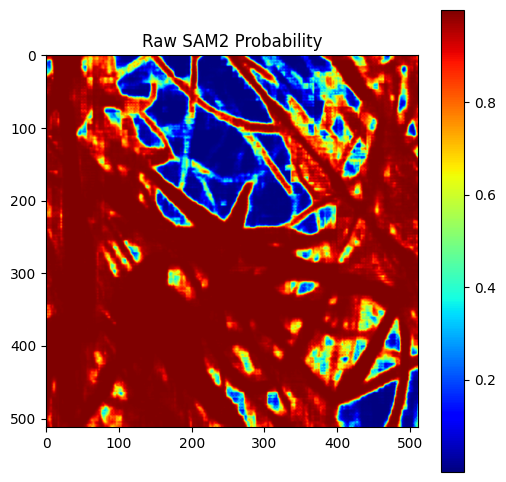

In [65]:
# Visualize raw SAM2 probability

prob = best_mask_probability.detach().cpu().numpy()

print("Min :", prob.min())
print("Max :", prob.max())
print("Mean:", prob.mean())
print("Std :", prob.std())

plt.figure(figsize=(6,6))
plt.imshow(prob, cmap="jet")
plt.colorbar()
plt.title("Raw SAM2 Probability")
plt.show()

In [66]:
#Define segmentation metrics 
def compute_binary_metrics(prediction, ground_truth):
    prediction = prediction.astype(bool)
    ground_truth = ground_truth.astype(bool)

    intersection = np.logical_and(
        prediction,
        ground_truth,
    ).sum()

    union = np.logical_or(
        prediction,
        ground_truth,
    ).sum()

    pred_pixels = prediction.sum()
    gt_pixels = ground_truth.sum()

    iou = (
        intersection / union
        if union > 0
        else 1.0
    )

    dice_denominator = pred_pixels + gt_pixels

    dice = (
        2.0 * intersection / dice_denominator
        if dice_denominator > 0
        else 1.0
    )

    precision = (
        intersection / pred_pixels
        if pred_pixels > 0
        else 0.0
    )

    recall = (
        intersection / gt_pixels
        if gt_pixels > 0
        else 0.0
    )

    return {
        "iou": float(iou),
        "dice": float(dice),
        "precision": float(precision),
        "recall": float(recall),
        "intersection": int(intersection),
        "union": int(union),
        "pred_pixels": int(pred_pixels),
        "gt_pixels": int(gt_pixels),
    }


metrics = compute_binary_metrics(
    pred_mask,
    gt_mask,
)

for name, value in metrics.items():
    if isinstance(value, float):
        print(f"{name:>14}: {value:.4f}")
    else:
        print(f"{name:>14}: {value}")

           iou: 0.9022
          dice: 0.9486
     precision: 0.9479
        recall: 0.9492
  intersection: 198036
         union: 219509
   pred_pixels: 208917
     gt_pixels: 208628


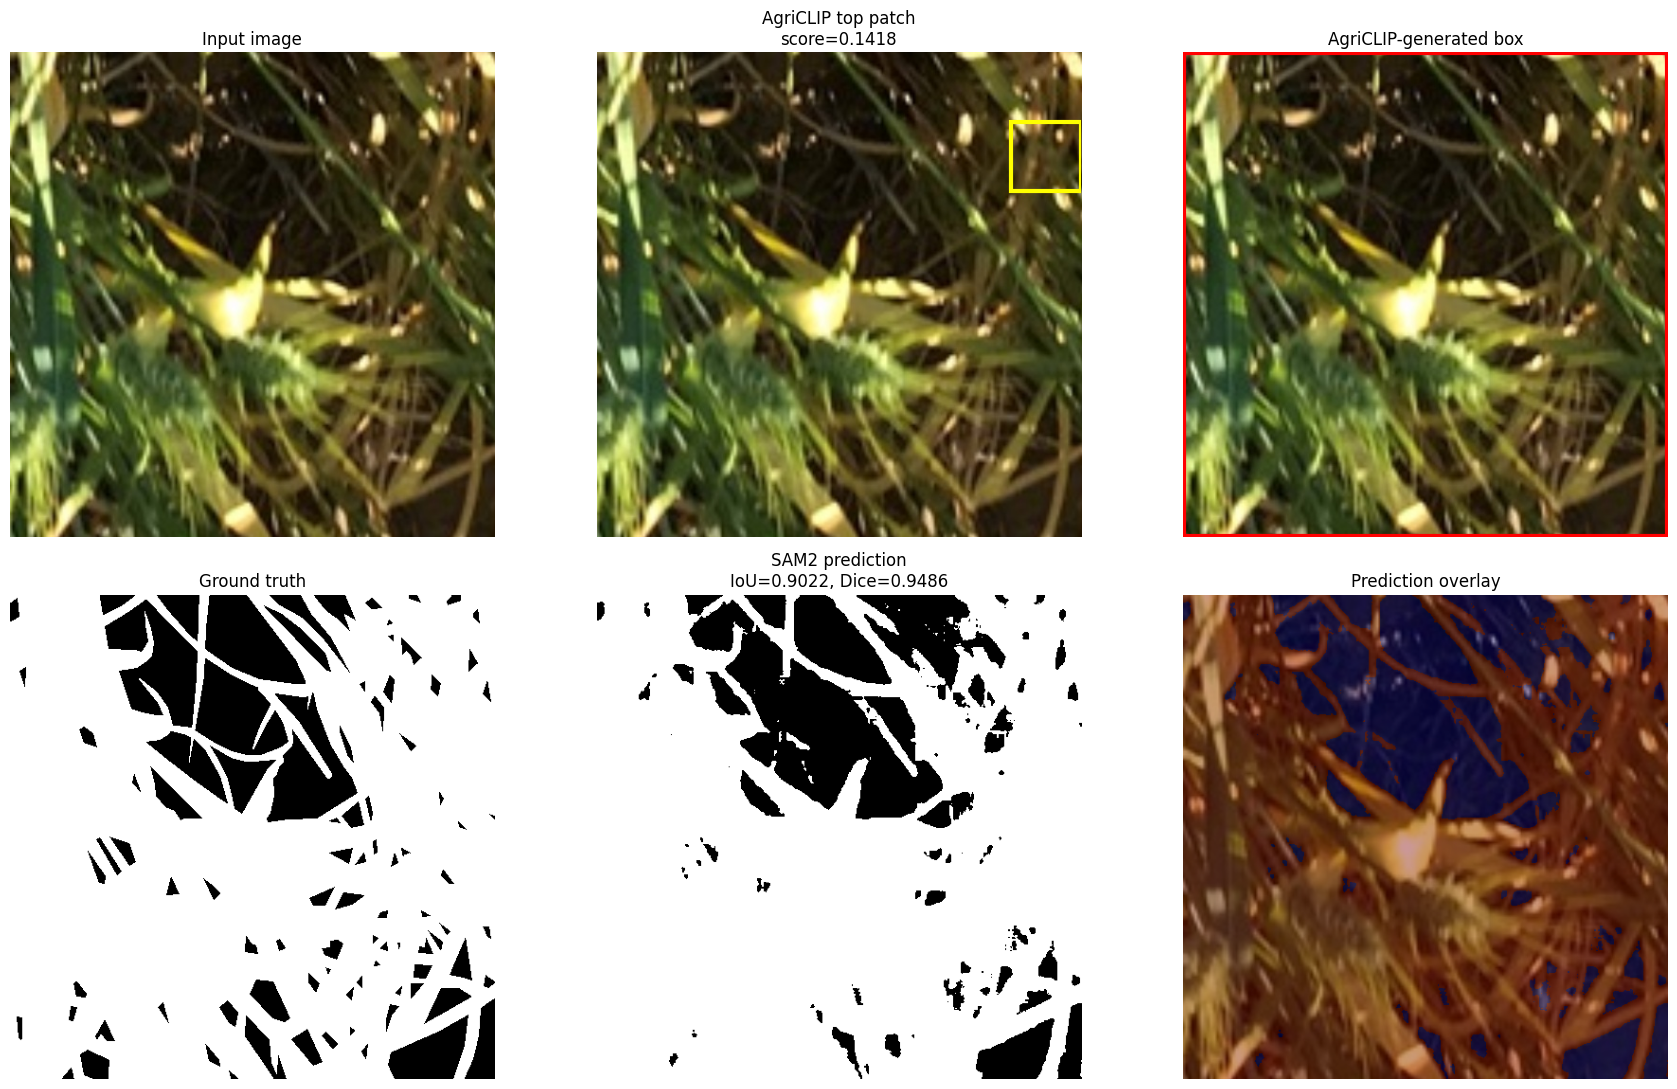

In [67]:
# Visualize the complete result

fig, ax = plt.subplots(
    2,
    3,
    figsize=(18, 11),
)

# Image
ax[0, 0].imshow(image)
ax[0, 0].set_title("Input image")
ax[0, 0].axis("off")



# Winning patch
best_patch = boxes[0]

ax[0, 1].imshow(image)

ax[0, 1].add_patch(
    plt.Rectangle(
        (best_patch[0], best_patch[1]),
        best_patch[2] - best_patch[0],
        best_patch[3] - best_patch[1],
        fill=False,
        edgecolor="yellow",
        linewidth=3,
    )
)

ax[0, 1].set_title(
    f"AgriCLIP top patch\nscore={scores[topk_indices[0]]:.4f}"
)

ax[0, 1].axis("off")


# Expanded AgriCLIP box
ax[0, 2].imshow(image)

ax[0, 2].add_patch(
    plt.Rectangle(
        (merged_box[0], merged_box[1]),
        merged_box[2] - merged_box[0],
        merged_box[3] - merged_box[1],
        fill=False,
        edgecolor="red",
        linewidth=3,
    )
)

ax[0, 2].set_title(
    "AgriCLIP-generated box"
)

ax[0, 2].axis("off")


# Ground truth
ax[1, 0].imshow(
    gt_mask,
    cmap="gray",
)

ax[1, 0].set_title(
    "Ground truth"
)

ax[1, 0].axis("off")


# Prediction
ax[1, 1].imshow(
    pred_mask,
    cmap="gray",
)

ax[1, 1].set_title(
    f"SAM2 prediction\n"
    f"IoU={metrics['iou']:.4f}, "
    f"Dice={metrics['dice']:.4f}"
)

ax[1, 1].axis("off")


# Overlay
ax[1, 2].imshow(image)

ax[1, 2].imshow(
    pred_mask,
    cmap="jet",
    alpha=0.40,
)

ax[1, 2].set_title(
    "Prediction overlay"
)

ax[1, 2].axis("off")


plt.tight_layout()
plt.show()

In [68]:

@torch.no_grad()
def generate_agriclip_box(
    image,
    top_k = 32

):

    # Extract DINO patches
    patch_features, grid_h, grid_w = extract_dino_patch_features(
        image
    )


    # Align to AgriCLIP space
    aligned_features = align_patch_features(
        patch_features
    )


    # Patch-text similarity
    patch_scores = (
        aligned_features 
        @ vegetation_embedding
    )


    scores = patch_scores.cpu().numpy()


    # Top-K patches
    topk_indices = np.argsort(scores)[::-1][:top_k]


    H, W = image.size[1], image.size[0]


    patch_h = H / grid_h
    patch_w = W / grid_w


    boxes = []


    for idx in topk_indices:

        r = idx // grid_w
        c = idx % grid_w


        x1 = int(c * patch_w)
        y1 = int(r * patch_h)

        x2 = int((c+1) * patch_w)
        y2 = int((r+1) * patch_h)


        boxes.append(
            [
                x1,
                y1,
                x2,
                y2
            ]
        )


    boxes = np.array(boxes)


    # Merge boxes
    xmin = boxes[:,0].min()
    ymin = boxes[:,1].min()

    xmax = boxes[:,2].max()
    ymax = boxes[:,3].max()


    margin = 25


    xmin = max(
        0,
        xmin-margin
    )

    ymin = max(
        0,
        ymin-margin
    )

    xmax = min(
        W-1,
        xmax+margin
    )

    ymax = min(
        H-1,
        ymax+margin
    )


    merged_box = np.array(
        [
            xmin,
            ymin,
            xmax,
            ymax
        ],
        dtype=np.int32
    )


    return (
        merged_box,
        boxes,
        scores,
        topk_indices
    )

In [69]:
#SAM2 prediction function 
@torch.no_grad()
def sam2_predict_box(
    image,
    box
):

    inputs = sam2_processor(
        images=image,
        input_boxes=[
            [
                box.tolist()
            ]
        ],
        return_tensors="pt",
    )


    inputs = {
        k:v.to(device)
        if torch.is_tensor(v)
        else v
        for k,v in inputs.items()
    }


    outputs = sam2_model(
        **inputs
    )


    # Best mask candidate

    best_idx = (
        outputs.iou_scores[0,0]
        .argmax()
        .item()
    )


    logits = outputs.pred_masks[
        0,
        0,
        best_idx
    ]


    probability = torch.sigmoid(
        logits
    )


    height = inputs["original_sizes"][0,0]
    width = inputs["original_sizes"][0,1]


    probability = F.interpolate(
        probability[None,None],
        size=(
            height,
            width
        ),
        mode="bilinear",
        align_corners=False,
    )[0,0]


    prediction = (
        probability > 0.5
    ).cpu().numpy().astype(np.uint8)


    confidence = (
        outputs.iou_scores[
            0,
            0,
            best_idx
        ]
        .item()
    )


    return prediction, confidence

In [70]:
import pandas as pd
from tqdm import tqdm

# Full validation loop
results = []
TOP_K = 32


for idx in tqdm(range(len(val_hf))):

    image = get_image(idx, split=val_hf)
    gt_mask = get_mask(idx, split=val_hf)

    try:
        # AgriCLIP localization
        agriclip_box, boxes, scores, topk_indices = generate_agriclip_box(
            image, TOP_K
        )

        # SAM2 segmentation
        pred_mask, confidence = sam2_predict_box(image, agriclip_box)

        # Metrics
        metrics = compute_binary_metrics(pred_mask, gt_mask)

        results.append(
            {
                "image_id": idx,
                "iou": metrics["iou"],
                "dice": metrics["dice"],
                "precision": metrics["precision"],
                "recall": metrics["recall"],
                "sam2_confidence": confidence,
            }
        )

    except Exception as e:
        print(f"Failed at image {idx}: {e}")
        raise e

print("\nFinished validation\n")

# ============================================================
# RESULTS AGGREGATION & PRINTING
# ============================================================
if len(results) > 0:
    results_df = pd.DataFrame(results)

    print("==================================================")
    print("           VALIDATION PERFORMANCE SUMMARY          ")
    print("==================================================")
    print(f"Total Evaluated Images:  {len(results_df)}")
    print(f"Mean Segmentation IoU:   {results_df['iou'].mean() * 100:.2f}%")
    print(f"Mean Dice Score:         {results_df['dice'].mean() * 100:.2f}%")
    print(f"Mean Precision:          {results_df['precision'].mean() * 100:.2f}%")
    print(f"Mean Recall:             {results_df['recall'].mean() * 100:.2f}%")
    print(f"Mean SAM2 Confidence:    {results_df['sam2_confidence'].mean():.4f}")
    print("==================================================")
else:
    print("No valid results computed.")


100%|██████████| 755/755 [00:31<00:00, 23.84it/s]


Finished validation

           VALIDATION PERFORMANCE SUMMARY          
Total Evaluated Images:  755
Mean Segmentation IoU:   84.03%
Mean Dice Score:         90.08%
Mean Precision:          89.01%
Mean Recall:             92.29%
Mean SAM2 Confidence:    0.9358


# Augmentation Code 

In [71]:
#Importing Augmentation Libraries
import random
import numpy as np
import torch
import torchvision.transforms.functional as TF
from PIL import Image
from torch.utils.data import Dataset, DataLoader


In [103]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

from datasets import load_dataset
from transformers import Sam2Model, Sam2Processor

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

PyTorch: 2.12.0+cu130
CUDA available: True
GPU: NVIDIA GeForce RTX 4090
Device: cuda


In [72]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA GeForce RTX 4090


In [75]:
#eXperimne settings 
MODEL_NAME = "facebook/sam2.1-hiera-tiny"

BATCH_SIZE = 1
NUM_EPOCHS = 10
LEARNING_RATE = 1e-4
NUM_WORKERS = 0

TOP_K = 32

AUG_CHECKPOINT_DIR = "sam2_vegann_augmentation_checkpoints"

os.makedirs(
    AUG_CHECKPOINT_DIR,
    exist_ok=True
)

print("Model:", MODEL_NAME)
print("Epochs:", NUM_EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Top-K:", TOP_K)

Model: facebook/sam2.1-hiera-tiny
Epochs: 10
Learning rate: 0.0001
Top-K: 32


In [ ]:
# Load and create split 
vegann = load_dataset("simonMadec/VegAnn")

print(vegann)
print("Columns:", vegann["train"].column_names)
print("Total images:", len(vegann["train"]))




DatasetDict({
    train: Dataset({
        features: ['image', 'mask', 'System', 'Orientation', 'latitude', 'longitude', 'date', 'LocAcc', 'Species', 'Owner', 'Dataset-Name', 'TVT-split1', 'TVT-split2', 'TVT-split3', 'TVT-split4', 'TVT-split5'],
        num_rows: 3775
    })
})
Columns: ['image', 'mask', 'System', 'Orientation', 'latitude', 'longitude', 'date', 'LocAcc', 'Species', 'Owner', 'Dataset-Name', 'TVT-split1', 'TVT-split2', 'TVT-split3', 'TVT-split4', 'TVT-split5']
Total images: 3775
DatasetDict({
    train: Dataset({
        features: ['image', 'mask', 'System', 'Orientation', 'latitude', 'longitude', 'date', 'LocAcc', 'Species', 'Owner', 'Dataset-Name', 'TVT-split1', 'TVT-split2', 'TVT-split3', 'TVT-split4', 'TVT-split5'],
        num_rows: 3775
    })
})
Columns: ['image', 'mask', 'System', 'Orientation', 'latitude', 'longitude', 'date', 'LocAcc', 'Species', 'Owner', 'Dataset-Name', 'TVT-split1', 'TVT-split2', 'TVT-split3', 'TVT-split4', 'TVT-split5']
Total images: 3775


In [77]:
split = vegann["train"].train_test_split(
    test_size=0.20,
    seed=42
)

train_hf = split["train"]
val_hf = split["test"]

print("Training images:", len(train_hf))
print("Validation images:", len(val_hf))

Training images: 3020
Validation images: 755


In [78]:
column_names = train_hf.column_names

image_candidates = [
    "image",
    "images",
    "rgb",
    "img"
]

mask_candidates = [
    "mask",
    "masks",
    "label",
    "labels",
    "segmentation_mask",
    "annotation"
]

IMAGE_KEY = next(
    (
        key for key in image_candidates
        if key in column_names
    ),
    None
)

MASK_KEY = next(
    (
        key for key in mask_candidates
        if key in column_names
    ),
    None
)

print("Image column:", IMAGE_KEY)
print("Mask column:", MASK_KEY)

if IMAGE_KEY is None or MASK_KEY is None:
    raise ValueError(
        f"Could not detect image/mask columns. "
        f"Available columns: {column_names}"
    )

Image column: image
Mask column: mask


In [79]:
def prepare_binary_mask(mask):
    """
    Convert a VegAnn mask into a binary NumPy mask.

    0 = background
    1 = vegetation
    """

    if isinstance(mask, Image.Image):
        mask = np.asarray(mask)

    elif torch.is_tensor(mask):
        mask = mask.detach().cpu().numpy()

    else:
        mask = np.asarray(mask)

    if mask.ndim == 3:
        mask = mask[..., 0]

    mask = (mask > 0).astype(np.uint8)

    return mask


def get_image(index, split):
    """
    Return an RGB PIL image.
    """

    image = split[index][IMAGE_KEY]

    if not isinstance(image, Image.Image):
        image = Image.fromarray(
            np.asarray(image)
        )

    return image.convert("RGB")


def get_mask(index, split):
    """
    Return a binary vegetation mask.
    """

    return prepare_binary_mask(
        split[index][MASK_KEY]
    )


def mask_to_box(mask, box_jitter=0):
    """
    Convert binary mask to [x1, y1, x2, y2].
    """

    y_indices, x_indices = np.where(mask > 0)

    if len(x_indices) == 0:
        return None

    x_min = int(x_indices.min())
    y_min = int(y_indices.min())
    x_max = int(x_indices.max())
    y_max = int(y_indices.max())

    height, width = mask.shape

    if box_jitter > 0:

        x_min -= random.randint(0, box_jitter)
        y_min -= random.randint(0, box_jitter)

        x_max += random.randint(0, box_jitter)
        y_max += random.randint(0, box_jitter)

    x_min = max(0, x_min)
    y_min = max(0, y_min)

    x_max = min(width - 1, x_max)
    y_max = min(height - 1, y_max)

    return [
        x_min,
        y_min,
        x_max,
        y_max
    ]

In [80]:
def augment_image_and_mask(
    image,
    mask,
    augmentation
):
    """
    Apply exactly the same spatial transformation
    to the image and segmentation mask.
    """

    if augmentation == "horizontal_flip":

        aug_image = image.transpose(
            Image.Transpose.FLIP_LEFT_RIGHT
        )

        aug_mask = np.fliplr(mask).copy()

    elif augmentation == "vertical_flip":

        aug_image = image.transpose(
            Image.Transpose.FLIP_TOP_BOTTOM
        )

        aug_mask = np.flipud(mask).copy()

    elif augmentation == "rotate_90":

        aug_image = image.rotate(
            90,
            expand=True
        )

        aug_mask = np.rot90(
            mask,
            k=1
        ).copy()

    elif augmentation == "rotate_180":

        aug_image = image.rotate(
            180,
            expand=True
        )

        aug_mask = np.rot90(
            mask,
            k=2
        ).copy()

    elif augmentation == "rotate_270":

        aug_image = image.rotate(
            270,
            expand=True
        )

        aug_mask = np.rot90(
            mask,
            k=3
        ).copy()

    else:

        raise ValueError(
            f"Unknown augmentation: {augmentation}"
        )

    return aug_image, aug_mask

In [81]:
EXPERIMENTS = {

    "A_Baseline": [],

    "B_HorizontalFlip": [
        "horizontal_flip"
    ],

    "C_VerticalFlip": [
        "vertical_flip"
    ],

    "D_Rotation": [
        "rotate_90",
        "rotate_180",
        "rotate_270"
    ],

    "E_Combined": [
        "horizontal_flip",
        "vertical_flip",
        "rotate_90",
        "rotate_180",
        "rotate_270"
    ]
}

for name, augmentations in EXPERIMENTS.items():

    print(
        name,
        "->",
        augmentations
    )

A_Baseline -> []
B_HorizontalFlip -> ['horizontal_flip']
C_VerticalFlip -> ['vertical_flip']
D_Rotation -> ['rotate_90', 'rotate_180', 'rotate_270']
E_Combined -> ['horizontal_flip', 'vertical_flip', 'rotate_90', 'rotate_180', 'rotate_270']


In [113]:
class AugmentedVegAnnSAM2Dataset(Dataset):

    def __init__(
        self,
        hf_dataset,
        image_key,
        mask_key,
        augmentations=None,
        box_jitter=10,
        skip_empty=False
    ):

        self.hf_dataset = hf_dataset
        self.image_key = image_key
        self.mask_key = mask_key

        self.augmentations = (
            augmentations
            if augmentations is not None
            else []
        )

        self.box_jitter = box_jitter

        self.valid_indices = []

        # Find images containing vegetation
        for index in range(len(hf_dataset)):

            item = hf_dataset[index]

            mask = prepare_binary_mask(
                item[self.mask_key]
            )

            if skip_empty and mask.sum() == 0:
                continue

            self.valid_indices.append(index)

    def __len__(self):

        # Original images
        original_count = len(
            self.valid_indices
        )

        # Each augmentation creates
        # another copy of every image
        augmented_count = (
            original_count
            * len(self.augmentations)
        )

        return (
            original_count
            + augmented_count
        )

    def __getitem__(self, index):

        original_count = len(
            self.valid_indices
        )

        # ------------------------------------------------
        # Original sample
        # ------------------------------------------------

        if index < original_count:

            original_index = (
                self.valid_indices[index]
            )

            augmentation = None

        # ------------------------------------------------
        # Augmented sample
        # ------------------------------------------------

        else:

            augmented_index = (
                index - original_count
            )

            original_position = (
                augmented_index
                // len(self.augmentations)
            )

            augmentation_position = (
                augmented_index
                % len(self.augmentations)
            )

            original_index = (
                self.valid_indices[
                    original_position
                ]
            )

            augmentation = (
                self.augmentations[
                    augmentation_position
                ]
            )

        item = self.hf_dataset[
            original_index
        ]

        image = item[self.image_key]

        if not isinstance(
            image,
            Image.Image
        ):

            image = Image.fromarray(
                np.asarray(image)
            )

        image = image.convert("RGB")

        mask = prepare_binary_mask(
            item[self.mask_key]
        )

        # ------------------------------------------------
        # Apply augmentation
        # ------------------------------------------------

        if augmentation is not None:

            image, mask = (
                augment_image_and_mask(
                    image,
                    mask,
                    augmentation
                )
            )

        # ------------------------------------------------
        # Create box AFTER augmentation
        # ------------------------------------------------

        box = mask_to_box(
            mask,
            box_jitter=self.box_jitter
        )

        if box is None:

            height, width = mask.shape

            box = [
                0,
                0,
                width - 1,
                height - 1
            ]

        return {
            "image": image,
            "mask": mask,
            "box": box,
            "index": original_index,
            "augmentation": augmentation
        }

In [114]:
#TEST THE DATASETS 
test_dataset = AugmentedVegAnnSAM2Dataset(
    hf_dataset=train_hf,
    image_key=IMAGE_KEY,
    mask_key=MASK_KEY,
    augmentations=["horizontal_flip"],
    box_jitter=10
)

print(
    "Original training images:",
    len(test_dataset.valid_indices)
)

print(
    "Dataset size with horizontal flip:",
    len(test_dataset)
)

print(
    "Expected approximately:",
    len(test_dataset.valid_indices) * 2
)

Original training images: 3020
Dataset size with horizontal flip: 6040
Expected approximately: 6040


In [115]:
#verify augmented sampples
original_sample = test_dataset[0]

augmented_sample = test_dataset[
    len(test_dataset.valid_indices)
]

print(
    "Original augmentation:",
    original_sample["augmentation"]
)

print(
    "Augmented sample:",
    augmented_sample["augmentation"]
)

print(
    "Original image:",
    original_sample["image"].size
)

print(
    "Augmented image:",
    augmented_sample["image"].size
)

Original augmentation: None
Augmented sample: horizontal_flip
Original image: (512, 512)
Augmented image: (512, 512)


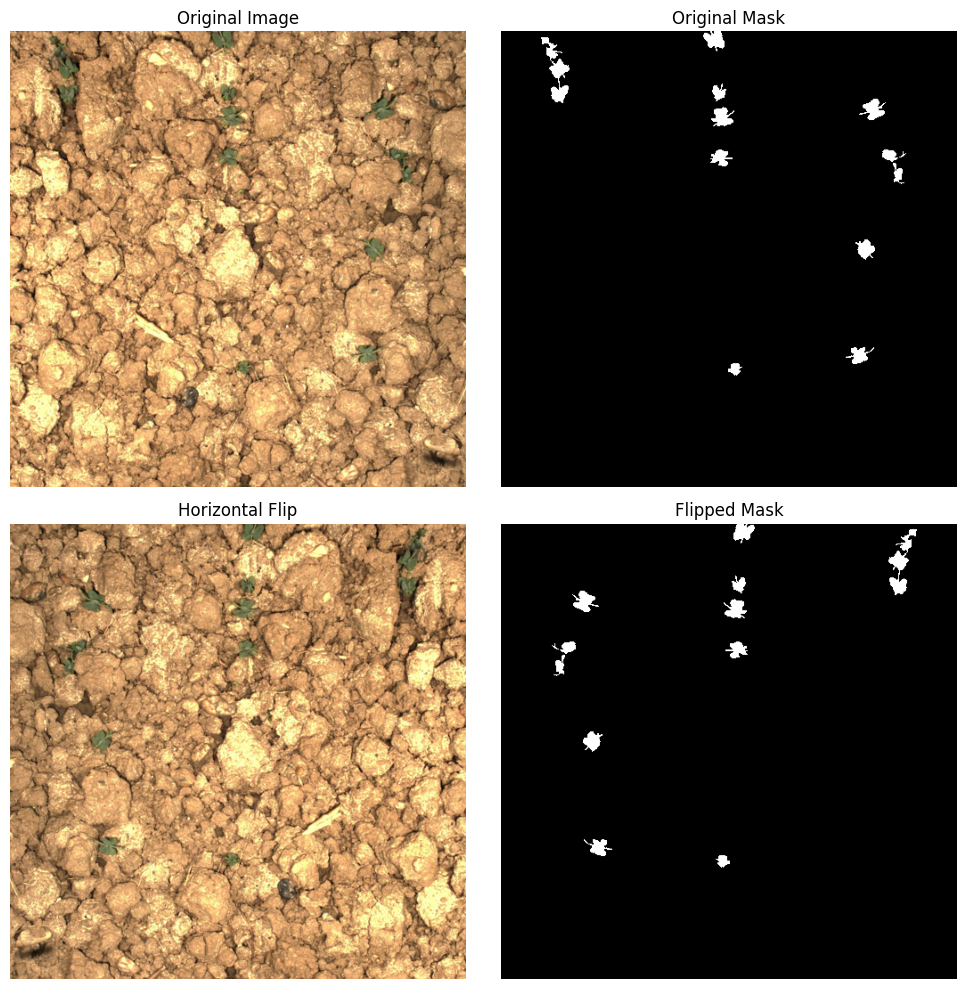

In [116]:
#visual verification 
original = test_dataset[0]
flipped = test_dataset[
    len(test_dataset.valid_indices)
]

fig, axes = plt.subplots(
    2,
    2,
    figsize=(10, 10)
)

axes[0, 0].imshow(
    original["image"]
)
axes[0, 0].set_title(
    "Original Image"
)
axes[0, 0].axis("off")

axes[0, 1].imshow(
    original["mask"],
    cmap="gray"
)
axes[0, 1].set_title(
    "Original Mask"
)
axes[0, 1].axis("off")

axes[1, 0].imshow(
    flipped["image"]
)
axes[1, 0].set_title(
    "Horizontal Flip"
)
axes[1, 0].axis("off")

axes[1, 1].imshow(
    flipped["mask"],
    cmap="gray"
)
axes[1, 1].set_title(
    "Flipped Mask"
)
axes[1, 1].axis("off")

plt.tight_layout()
plt.show()

In [91]:
def sam2_collate_fn(batch):

    return {
        "images": [
            item["image"]
            for item in batch
        ],

        "masks": [
            item["mask"]
            for item in batch
        ],

        "boxes": [
            item["box"]
            for item in batch
        ],

        "indices": [
            item["index"]
            for item in batch
        ]
    }

In [117]:
#create validation dataset 
#no augmentation here
val_dataset = AugmentedVegAnnSAM2Dataset(
    hf_dataset=val_hf,
    image_key=IMAGE_KEY,
    mask_key=MASK_KEY,
    augmentations=[],
    box_jitter=0
)

print(
    "Validation images:",
    len(val_dataset)
)

Validation images: 755


In [118]:
#creae validation dataloader 
val_loader = DataLoader(
    val_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
    collate_fn=sam2_collate_fn
)

print(
    "Validation batches:",
    len(val_loader)
)

Validation batches: 755


In [119]:
#SAM2 loading 
def create_sam2_model():

    processor = Sam2Processor.from_pretrained(
        MODEL_NAME
    )

    model = Sam2Model.from_pretrained(
        MODEL_NAME
    )

    model = model.to(device)

    # Freeze everything
    for parameter in model.parameters():
        parameter.requires_grad = False

    # Locate mask decoder
    if hasattr(model, "mask_decoder"):

        mask_decoder = model.mask_decoder

    elif hasattr(
        model,
        "sam_mask_decoder"
    ):

        mask_decoder = (
            model.sam_mask_decoder
        )

    else:

        mask_decoder = None

        for name, module in (
            model.named_modules()
        ):

            if name.endswith(
                "mask_decoder"
            ):

                mask_decoder = module
                break

    if mask_decoder is None:

        raise AttributeError(
            "SAM2 mask decoder not found."
        )

    # Unfreeze mask decoder
    for parameter in (
        mask_decoder.parameters()
    ):

        parameter.requires_grad = True

    model.eval()

    return (
        processor,
        model,
        mask_decoder
    )

In [104]:
#loss functions 
bce_loss_fn = nn.BCEWithLogitsLoss()


def dice_loss(
    logits,
    targets,
    smooth=1.0
):

    probabilities = torch.sigmoid(
        logits
    )

    probabilities = (
        probabilities.flatten(1)
    )

    targets = targets.flatten(1)

    intersection = (
        probabilities * targets
    ).sum(dim=1)

    dice = (
        2.0 * intersection + smooth
    ) / (
        probabilities.sum(dim=1)
        + targets.sum(dim=1)
        + smooth
    )

    return 1.0 - dice.mean()


def combined_segmentation_loss(
    logits,
    targets
):

    bce = bce_loss_fn(
        logits,
        targets
    )

    dice = dice_loss(
        logits,
        targets
    )

    total = (
        0.5 * bce
        +
        0.5 * dice
    )

    return total, bce, dice

In [105]:
#extract mask 
def extract_single_mask_logits(
    pred_masks
):

    logits = pred_masks

    while logits.ndim > 3:

        logits = logits[:, 0]

    return logits

In [106]:
def prepare_sam2_batch(
    batch,
    processor
):

    images = batch["images"]
    masks = batch["masks"]
    boxes = batch["boxes"]

    input_boxes = [
        [box]
        for box in boxes
    ]

    inputs = processor(
        images=images,
        segmentation_maps=masks,
        input_boxes=input_boxes,
        return_tensors="pt"
    )

    inputs = {
        key: value.to(device)
        if torch.is_tensor(value)
        else value

        for key, value in inputs.items()
    }

    return inputs

In [107]:
def train_one_epoch(
    model,
    processor,
    loader,
    optimizer,
    scaler
):

    model.train()

    running_loss = 0.0
    running_bce = 0.0
    running_dice = 0.0

    for batch in tqdm(
        loader,
        desc="Training",
        leave=False
    ):

        inputs = prepare_sam2_batch(
            batch,
            processor
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        # Frozen vision encoder
        with torch.no_grad():

            image_embeddings = (
                model.get_image_embeddings(
                    inputs["pixel_values"]
                )
            )

        with torch.amp.autocast(
            "cuda",
            enabled=torch.cuda.is_available()
        ):

            outputs = model(
                image_embeddings=image_embeddings,
                input_boxes=inputs["input_boxes"],
                multimask_output=False
            )

            logits = (
                extract_single_mask_logits(
                    outputs.pred_masks
                )
            )

            targets = (
                inputs["labels"]
                .float()
            )

            while targets.ndim > 3:
                targets = targets[:, 0]

            targets = F.interpolate(
                targets.unsqueeze(1),
                size=logits.shape[-2:],
                mode="nearest"
            ).squeeze(1)

            targets = (
                targets > 0
            ).float()

            loss, bce, dice = (
                combined_segmentation_loss(
                    logits,
                    targets
                )
            )

        scaler.scale(
            loss
        ).backward()

        scaler.unscale_(
            optimizer
        )

        torch.nn.utils.clip_grad_norm_(
            model.mask_decoder.parameters(),
            max_norm=1.0
        )

        scaler.step(
            optimizer
        )

        scaler.update()

        running_loss += loss.item()
        running_bce += bce.item()
        running_dice += dice.item()

    n = len(loader)

    return {
        "loss": running_loss / n,
        "bce": running_bce / n,
        "dice_loss": running_dice / n
    }

In [108]:
@torch.no_grad()
def validate(
    model,
    processor,
    loader,
    threshold=0.5
):

    model.eval()

    iou_values = []
    dice_values = []

    precision_values = []
    recall_values = []

    confidence_values = []

    for batch in tqdm(
        loader,
        desc="Validation",
        leave=False
    ):

        inputs = prepare_sam2_batch(
            batch,
            processor
        )

        image_embeddings = (
            model.get_image_embeddings(
                inputs["pixel_values"]
            )
        )

        outputs = model(
            image_embeddings=image_embeddings,
            input_boxes=inputs["input_boxes"],
            multimask_output=False
        )

        logits = (
            extract_single_mask_logits(
                outputs.pred_masks
            )
        )

        probabilities = torch.sigmoid(
            logits
        )

        predictions = (
            probabilities >= threshold
        ).float()

        targets = (
            inputs["labels"]
            .float()
        )

        while targets.ndim > 3:
            targets = targets[:, 0]

        targets = F.interpolate(
            targets.unsqueeze(1),
            size=predictions.shape[-2:],
            mode="nearest"
        ).squeeze(1)

        targets = (
            targets > 0
        ).float()

        # Flatten per image
        pred_flat = predictions.flatten(1)
        target_flat = targets.flatten(1)

        intersection = (
            pred_flat * target_flat
        ).sum(dim=1)

        pred_sum = (
            pred_flat.sum(dim=1)
        )

        target_sum = (
            target_flat.sum(dim=1)
        )

        union = (
            pred_sum
            +
            target_sum
            -
            intersection
        )

        iou = (
            intersection + 1e-7
        ) / (
            union + 1e-7
        )

        dice = (
            2 * intersection + 1e-7
        ) / (
            pred_sum
            +
            target_sum
            +
            1e-7
        )

        true_positive = intersection

        precision = (
            true_positive + 1e-7
        ) / (
            pred_sum + 1e-7
        )

        recall = (
            true_positive + 1e-7
        ) / (
            target_sum + 1e-7
        )

        iou_values.extend(
            iou.cpu().numpy()
        )

        dice_values.extend(
            dice.cpu().numpy()
        )

        precision_values.extend(
            precision.cpu().numpy()
        )

        recall_values.extend(
            recall.cpu().numpy()
        )

        # SAM2 confidence
        confidence = (
            outputs.iou_scores
            .reshape(-1)
            .cpu()
            .numpy()
        )

        confidence_values.extend(
            confidence
        )

    return {

        "iou":
            np.mean(iou_values),

        "dice":
            np.mean(dice_values),

        "precision":
            np.mean(precision_values),

        "recall":
            np.mean(recall_values),

        "sam2_confidence":
            np.mean(confidence_values),

        "images":
            len(iou_values)
    }

In [128]:

# CONFIGURE SAM2 FOR MASK-DECODER-ONLY FINE-TUNING


# Freeze EVERYTHING
for parameter in sam2_model.parameters():
    parameter.requires_grad = False


# Unfreeze ONLY the mask decoder
for parameter in sam2_model.mask_decoder.parameters():
    parameter.requires_grad = True


# ------------------------------------------------------------
# Count parameters
# ------------------------------------------------------------

total_params = sum(
    p.numel()
    for p in sam2_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in sam2_model.parameters()
    if p.requires_grad
)

frozen_params = total_params - trainable_params


print("============================================================")
print("SAM2 TRAINING CONFIGURATION")
print("============================================================")

print(
    f"Total parameters:     "
    f"{total_params:,} "
    f"({total_params / 1e6:.2f}M)"
)

print(
    f"Trainable parameters: "
    f"{trainable_params:,} "
    f"({trainable_params / 1e6:.2f}M)"
)

print(
    f"Frozen parameters:    "
    f"{frozen_params:,} "
    f"({frozen_params / 1e6:.2f}M)"
)

print(
    f"Trainable percentage: "
    f"{100 * trainable_params / total_params:.2f}%"
)

print("============================================================")

SAM2 TRAINING CONFIGURATION
Total parameters:     31,440,721 (31.44M)
Trainable parameters: 4,215,109 (4.22M)
Frozen parameters:    27,225,612 (27.23M)
Trainable percentage: 13.41%


In [131]:
# ============================================================
# VERIFY THAT ONLY MASK DECODER IS TRAINABLE
# ============================================================

non_decoder_trainable = []

decoder_trainable_count = 0

for name, parameter in sam2_model.named_parameters():

    if parameter.requires_grad:

        if "mask_decoder" not in name:
            non_decoder_trainable.append(name)

        else:
            decoder_trainable_count += parameter.numel()


print("============================================================")
print("TRAINABLE PARAMETER VERIFICATION")
print("============================================================")

if len(non_decoder_trainable) == 0:

    print(
        " ONLY MASK DECODER PARAMETERS ARE TRAINABLE."
    )

else:

    print(
        " ERROR: OTHER PARAMETERS ARE TRAINABLE."
    )

    for name in non_decoder_trainable[:20]:
        print(" ", name)


print(
    f"\nMask decoder trainable parameters: "
    f"{decoder_trainable_count:,}"
)

print("============================================================")

TRAINABLE PARAMETER VERIFICATION
 ONLY MASK DECODER PARAMETERS ARE TRAINABLE.

Mask decoder trainable parameters: 4,215,109


In [130]:


optimizer = torch.optim.AdamW(
    [
        parameter
        for parameter in sam2_model.parameters()
        if parameter.requires_grad
    ],
    lr=1e-4,
    weight_decay=1e-4
)

print("Optimizer created.")
print(
    "Optimizer parameter tensors:",
    sum(
        len(group["params"])
        for group in optimizer.param_groups
    )
)

Optimizer created.
Optimizer parameter tensors: 131


In [110]:
#AUGMENTATION FUNCTION FOR ALL 
def run_augmentation_experiment(
    experiment_name,
    augmentations
):

    print("\n")
    print("=" * 70)
    print(
        f"STARTING EXPERIMENT: {experiment_name}"
    )
    print("=" * 70)

    print(
        "Augmentations:",
        augmentations
    )

    # ------------------------------------------------
    # Create training dataset
    # ------------------------------------------------

    train_dataset = (
        AugmentedVegAnnSAM2Dataset(
            hf_dataset=train_hf,
            image_key=IMAGE_KEY,
            mask_key=MASK_KEY,
            augmentations=augmentations,
            box_jitter=10
        )
    )

    print(
        "Training images:",
        len(train_dataset)
    )

    # ------------------------------------------------
    # Training loader
    # ------------------------------------------------

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=True,
        collate_fn=sam2_collate_fn
    )

    # ------------------------------------------------
    # Fresh SAM2 model
    # ------------------------------------------------

    processor, model, mask_decoder = (
        create_sam2_model()
    )

    print(
        "Trainable parameters:",
        sum(
            p.numel()
            for p in model.parameters()
            if p.requires_grad
        )
    )

    # ------------------------------------------------
    # Optimizer
    # ------------------------------------------------

    optimizer = create_optimizer(
        model
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=torch.cuda.is_available()
    )

    # ------------------------------------------------
    # Training history
    # ------------------------------------------------

    history = {
        "train_loss": [],
        "val_iou": [],
        "val_dice": []
    }

    best_iou = -1.0

    checkpoint_path = os.path.join(
        AUG_CHECKPOINT_DIR,
        f"{experiment_name}.pt"
    )

    # ------------------------------------------------
    # Epoch loop
    # ------------------------------------------------

    for epoch in range(
        NUM_EPOCHS
    ):

        print("\n")
        print(
            f"{experiment_name} "
            f"| Epoch {epoch + 1}/{NUM_EPOCHS}"
        )

        train_results = (
            train_one_epoch(
                model=model,
                processor=processor,
                loader=train_loader,
                optimizer=optimizer,
                scaler=scaler
            )
        )

        val_results = validate(
            model=model,
            processor=processor,
            loader=val_loader
        )

        history[
            "train_loss"
        ].append(
            train_results["loss"]
        )

        history[
            "val_iou"
        ].append(
            val_results["iou"]
        )

        history[
            "val_dice"
        ].append(
            val_results["dice"]
        )

        print(
            f"Train Loss: "
            f"{train_results['loss']:.4f}"
        )

        print(
            f"Validation IoU: "
            f"{100 * val_results['iou']:.2f}%"
        )

        print(
            f"Validation Dice: "
            f"{100 * val_results['dice']:.2f}%"
        )

        # ------------------------------------------------
        # Save best model
        # ------------------------------------------------

        if val_results["iou"] > best_iou:

            best_iou = (
                val_results["iou"]
            )

            torch.save(
                {
                    "experiment":
                        experiment_name,

                    "augmentations":
                        augmentations,

                    "epoch":
                        epoch + 1,

                    "model_name":
                        MODEL_NAME,

                    "mask_decoder_state_dict":
                        mask_decoder.state_dict(),

                    "best_iou":
                        best_iou,

                    "history":
                        history
                },
                checkpoint_path
            )

            print(
                "Saved best checkpoint:"
            )

            print(
                checkpoint_path
            )

    # ------------------------------------------------
    # Load best model
    # ------------------------------------------------

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )

    mask_decoder.load_state_dict(
        checkpoint[
            "mask_decoder_state_dict"
        ]
    )

    # ------------------------------------------------
    # Final evaluation
    # ------------------------------------------------

    final_results = validate(
        model=model,
        processor=processor,
        loader=val_loader
    )

    print("\n")
    print("=" * 70)
    print(
        f"FINAL RESULT: {experiment_name}"
    )
    print("=" * 70)

    print(
        f"Images:       {final_results['images']}"
    )

    print(
        f"IoU:          "
        f"{100 * final_results['iou']:.2f}%"
    )

    print(
        f"Dice:         "
        f"{100 * final_results['dice']:.2f}%"
    )

    print(
        f"Precision:    "
        f"{100 * final_results['precision']:.2f}%"
    )

    print(
        f"Recall:       "
        f"{100 * final_results['recall']:.2f}%"
    )

    print(
        f"Confidence:   "
        f"{final_results['sam2_confidence']:.4f}"
    )

    print("=" * 70)

    return {
        "experiment":
            experiment_name,

        "augmentations":
            augmentations,

        "images":
            final_results["images"],

        "iou":
            final_results["iou"],

        "dice":
            final_results["dice"],

        "precision":
            final_results["precision"],

        "recall":
            final_results["recall"],

        "sam2_confidence":
            final_results["sam2_confidence"],

        "checkpoint":
            checkpoint_path,

        "history":
            history
    }

In [124]:
# ============================================================
# CURRENT SAM2 TRAINABLE PARAMETER COUNT
# ============================================================

total_params = sum(
    p.numel()
    for p in sam2_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in sam2_model.parameters()
    if p.requires_grad
)

frozen_params = total_params - trainable_params

print("============================================================")
print("CURRENT SAM2 PARAMETER STATUS")
print("============================================================")

print(
    f"Total parameters:     {total_params:,} "
    f"({total_params / 1e6:.2f}M)"
)

print(
    f"Trainable parameters: {trainable_params:,} "
    f"({trainable_params / 1e6:.2f}M)"
)

print(
    f"Frozen parameters:    {frozen_params:,} "
    f"({frozen_params / 1e6:.2f}M)"
)

print(
    f"Trainable percentage: "
    f"{100 * trainable_params / total_params:.2f}%"
)

print("============================================================")

CURRENT SAM2 PARAMETER STATUS
Total parameters:     31,440,721 (31.44M)
Trainable parameters: 31,440,721 (31.44M)
Frozen parameters:    0 (0.00M)
Trainable percentage: 100.00%


## Horizontal flip

In [111]:
result_B = run_augmentation_experiment(
    experiment_name="B_HorizontalFlip",
    augmentations=[
        "horizontal_flip"
    ]
)



STARTING EXPERIMENT: B_HorizontalFlip
Augmentations: ['horizontal_flip']
Training images: 5932


[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Trainable parameters: 4215109


B_HorizontalFlip | Epoch 1/10


Train Loss: 0.1566
Validation IoU: 85.47%
Validation Dice: 91.57%
Saved best checkpoint:
sam2_vegann_augmentation_checkpoints/B_HorizontalFlip.pt


B_HorizontalFlip | Epoch 2/10


Train Loss: 0.1310
Validation IoU: 86.78%
Validation Dice: 92.38%
Saved best checkpoint:
sam2_vegann_augmentation_checkpoints/B_HorizontalFlip.pt


B_HorizontalFlip | Epoch 3/10


... (5 outputs left out)

Train Loss: 0.1039
Validation IoU: 87.24%
Validation Dice: 92.72%


B_HorizontalFlip | Epoch 9/10


Train Loss: 0.1017
Validation IoU: 87.25%
Validation Dice: 92.73%


B_HorizontalFlip | Epoch 10/10


Train Loss: 0.0994
Validation IoU: 87.52%
Validation Dice: 92.91%




FINAL RESULT: B_HorizontalFlip
Images:       746
IoU:          87.56%
Dice:         92.95%
Precision:    92.64%
Recall:       93.83%
Confidence:   0.9420


In [132]:
result_C = run_augmentation_experiment(
    experiment_name="C_VerticalFlip",
    augmentations=[
        "vertical_flip"
    ]
)



STARTING EXPERIMENT: C_VerticalFlip
Augmentations: ['vertical_flip']
Training images: 6040


[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Trainable parameters: 4215109


C_VerticalFlip | Epoch 1/10


Train Loss: 0.1725
Validation IoU: 84.86%
Validation Dice: 90.92%
Saved best checkpoint:
sam2_vegann_augmentation_checkpoints/C_VerticalFlip.pt


C_VerticalFlip | Epoch 2/10


Train Loss: 0.1420
Validation IoU: 86.23%
Validation Dice: 91.92%
Saved best checkpoint:
sam2_vegann_augmentation_checkpoints/C_VerticalFlip.pt


C_VerticalFlip | Epoch 3/10


... (5 outputs left out)

Train Loss: 0.1109
Validation IoU: 87.40%
Validation Dice: 92.76%


C_VerticalFlip | Epoch 9/10


Train Loss: 0.1081
Validation IoU: 87.36%
Validation Dice: 92.70%


C_VerticalFlip | Epoch 10/10


Train Loss: 0.1063
Validation IoU: 87.37%
Validation Dice: 92.72%




FINAL RESULT: C_VerticalFlip
Images:       755
IoU:          87.41%
Dice:         92.75%
Precision:    93.07%
Recall:       93.12%
Confidence:   0.9376


In [135]:
result_D = run_augmentation_experiment(
    experiment_name="D_Rotation",
    augmentations=[
        "rotate_90",
        "rotate_180",
        "rotate_270"
    ]
)



STARTING EXPERIMENT: D_Rotation
Augmentations: ['rotate_90', 'rotate_180', 'rotate_270']
Training images: 12080


[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Trainable parameters: 4215109


D_Rotation | Epoch 1/10


Train Loss: 0.1604
Validation IoU: 86.53%
Validation Dice: 92.18%
Saved best checkpoint:
sam2_vegann_augmentation_checkpoints/D_Rotation.pt


D_Rotation | Epoch 2/10


Train Loss: 0.1343
Validation IoU: 86.94%
Validation Dice: 92.43%
Saved best checkpoint:
sam2_vegann_augmentation_checkpoints/D_Rotation.pt


D_Rotation | Epoch 3/10


... (5 outputs left out)

Train Loss: 0.1062
Validation IoU: 87.57%
Validation Dice: 92.83%


D_Rotation | Epoch 9/10


Train Loss: 0.1039
Validation IoU: 87.80%
Validation Dice: 93.04%
Saved best checkpoint:
sam2_vegann_augmentation_checkpoints/D_Rotation.pt


D_Rotation | Epoch 10/10


Train Loss: 0.1012
Validation IoU: 87.67%
Validation Dice: 92.89%




FINAL RESULT: D_Rotation
Images:       755
IoU:          87.80%
Dice:         93.04%
Precision:    92.78%
Recall:       93.92%
Confidence:   0.9564


In [136]:
result_E = run_augmentation_experiment(
    experiment_name="E_Combined",
    augmentations=[
        "horizontal_flip",
        "vertical_flip",
        "rotate_90",
        "rotate_180",
        "rotate_270"
    ]
)



STARTING EXPERIMENT: E_Combined
Augmentations: ['horizontal_flip', 'vertical_flip', 'rotate_90', 'rotate_180', 'rotate_270']


Training images: 18120


[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Trainable parameters: 4215109


E_Combined | Epoch 1/10


Train Loss: 0.1524
Validation IoU: 87.04%
Validation Dice: 92.56%
Saved best checkpoint:
sam2_vegann_augmentation_checkpoints/E_Combined.pt


E_Combined | Epoch 2/10


... (6 outputs left out)

Train Loss: 0.0985
Validation IoU: 88.02%
Validation Dice: 93.24%
Saved best checkpoint:
sam2_vegann_augmentation_checkpoints/E_Combined.pt


E_Combined | Epoch 9/10


Train Loss: 0.0954
Validation IoU: 88.02%
Validation Dice: 93.22%


E_Combined | Epoch 10/10


Train Loss: 0.0941
Validation IoU: 87.94%
Validation Dice: 93.16%




FINAL RESULT: E_Combined
Images:       755
IoU:          88.02%
Dice:         93.24%
Precision:    93.50%
Recall:       93.37%
Confidence:   0.9508


In [137]:
augmentation_results = [
    {
        "Experiment": "A — Baseline",
        "Augmentation": "None",
        "Images": 755,
        "IoU": 84.03,
        "Dice": 90.08,
        "Precision": 89.01,
        "Recall": 92.29,
        "SAM2 Confidence": 0.9358
    }
]

for result in [
    result_B,
    result_C,
    result_D,
    result_E
]:

    augmentation_results.append(
        {
            "Experiment":
                result["experiment"],

            "Augmentation":
                "+".join(
                    result["augmentations"]
                ),

            "Images":
                result["images"],

            "IoU":
                result["iou"] * 100,

            "Dice":
                result["dice"] * 100,

            "Precision":
                result["precision"] * 100,

            "Recall":
                result["recall"] * 100,

            "SAM2 Confidence":
                result["sam2_confidence"]
        }
    )

augmentation_df = pd.DataFrame(
    augmentation_results
)

augmentation_df

,Experiment,Augmentation,Images,IoU,Dice,Precision,Recall,SAM2 Confidence
0,A — Baseline,None,755,84.030000,90.080000,89.010000,92.290000,0.935800
1,B_HorizontalFlip,horizontal_flip,746,87.556549,92.948608,92.640289,93.827606,0.941989
2,C_VerticalFlip,vertical_flip,755,87.412125,92.746277,93.069717,93.124847,0.937634
3,D_Rotation,rotate_90+rotate_180+rotate_270,755,87.804123,93.035522,92.775871,93.924942,0.956396
4,E_Combined,horizontal_flip+vertical_flip+rotate_90+rotate...,755,88.024315,93.235962,93.502190,93.369125,0.950818


In [138]:
baseline_iou = 84.03

augmentation_df[
    "IoU Improvement"
] = (
    augmentation_df["IoU"]
    -
    baseline_iou
)

augmentation_df[
    "Relative Improvement (%)"
] = (
    augmentation_df["IoU Improvement"]
    /
    baseline_iou
) * 100

augmentation_df

,Experiment,Augmentation,Images,IoU,Dice,Precision,Recall,SAM2 Confidence,IoU Improvement,Relative Improvement (%)
0,A — Baseline,None,755,84.030000,90.080000,89.010000,92.290000,0.935800,0.000000,0.000000
1,B_HorizontalFlip,horizontal_flip,746,87.556549,92.948608,92.640289,93.827606,0.941989,3.526549,4.196774
2,C_VerticalFlip,vertical_flip,755,87.412125,92.746277,93.069717,93.124847,0.937634,3.382125,4.024901
3,D_Rotation,rotate_90+rotate_180+rotate_270,755,87.804123,93.035522,92.775871,93.924942,0.956396,3.774123,4.491399
4,E_Combined,horizontal_flip+vertical_flip+rotate_90+rotate...,755,88.024315,93.235962,93.502190,93.369125,0.950818,3.994315,4.753439


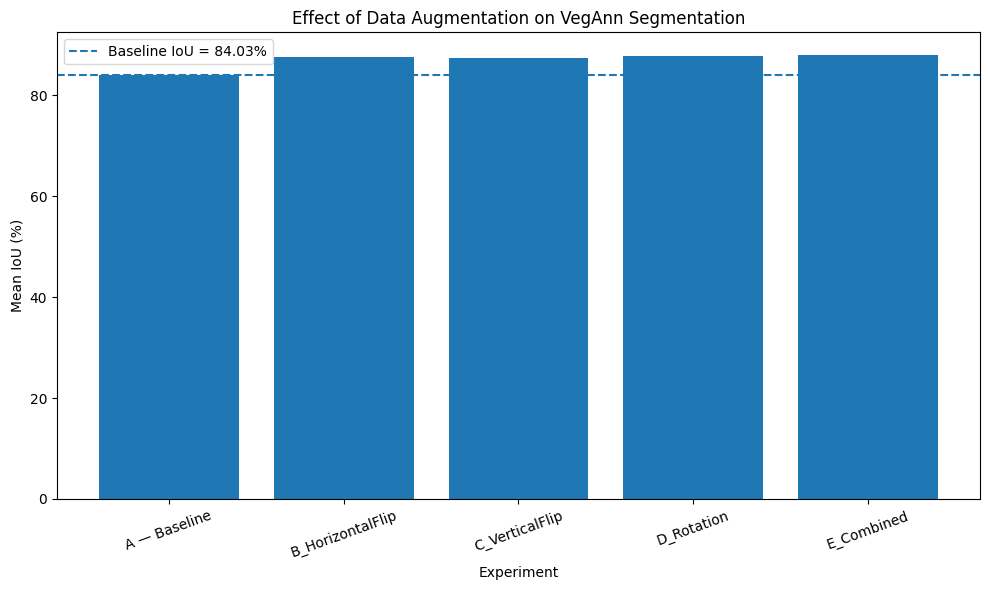

In [139]:
plt.figure(figsize=(10, 6))

plt.bar(
    augmentation_df["Experiment"],
    augmentation_df["IoU"]
)

plt.axhline(
    y=84.03,
    linestyle="--",
    label="Baseline IoU = 84.03%"
)

plt.ylabel("Mean IoU (%)")
plt.xlabel("Experiment")
plt.title(
    "Effect of Data Augmentation on VegAnn Segmentation"
)

plt.xticks(
    rotation=20
)

plt.legend()
plt.tight_layout()
plt.show()